# 08 · Model diagnostics: peaks, uncertainty, risk tiers, interpretability, deployable bundle

Uses the champion fixed in notebook 07 (`reports/model_tournament/champion.json`). Every calibration parameter, alert
threshold and correction for outer season *Y* is learned on seasons before *Y* only. Convention B is primary.
**2025 is not loaded.**

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from cycler import cycler
import time
from scipy.stats import poisson, nbinom
from dengueshield.data import load_development_panel, RAW_PATH, sha256
from dengueshield.models import seasons as S
from dengueshield.models.zoo import make
from dengueshield.calibration import intervals as I, peaks as PK, risk as R

OUT = ROOT / "reports/model_tournament"; FIG = OUT / "figures"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES), "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

panel = load_development_panel(); assert panel.date.dt.year.max() == 2024
FS = S.feature_sets(panel)
CH = json.loads((OUT / "champion.json").read_text())
print(json.dumps(CH, indent=1)[:1500])
def champ_preds(conv):
    out = []
    for h in (2, 3, 4):
        c = CH["per_horizon"][str(h)]
        for yr in S.SEASONS:
            out.append(S.predict_season(panel, conv, c["fs"], FS[c["fs"]], c["model"], c["params"], h, yr, c.get("tag", "")))
    return pd.concat(out, ignore_index=True)
CB, CA = champ_preds("B"), champ_preds("A")
D = {}

{
 "convention_primary": "B_start_of_week",
 "rule": "see notebook 07 section 6",
 "failed_models": {
  "glm_nb": "unpenalised NB IRLS diverged in short-history seasons (season MAE 2.47 in 2018, 1.95 in 2019)",
  "lgbm_l1": "point forecast only (no predictive distribution, so no intervals or expected cases)"
 },
 "per_horizon": {
  "2": {
   "model": "glm_poisson",
   "fs": "F8",
   "tag": "",
   "params": {}
  },
  "3": {
   "model": "glm_poisson",
   "fs": "F8",
   "tag": "",
   "params": {}
  },
  "4": {
   "model": "glm_poisson",
   "fs": "F8",
   "tag": "",
   "params": {}
  }
 },
 "best_scoring_alternative_B_bench": {
  "model": "ens_glm+spline",
  "fs": "F3",
  "tag": "ensemble",
  "mae_avg": 1.335287118551124
 },
 "validation": {
  "B": {
   "2": {
    "bench_2022_2024": {
     "mae": 1.107,
     "rmse": 2.2205,
     "mae_mean": 1.1608,
     "rmse_mean": 2.2055,
     "high_mae": 3.9336,
     "high_bias": -2.541,
     "recall": 0.6236,
     "precision": 0.7705,
     "false_alert

## 1. High-incidence underprediction (convention B, outer seasons 2019–2024)

High-incidence week = actual ≥ the training-fold q90 (9–10 cases; a data-derived operating point, **not** an epidemiological
threshold). Methods: median (baseline), mean, isotonic recalibration of the mean, a limited multiplier on predicted means ≥ the
training q80, an upper Poisson quantile, LightGBM quantile regression (α = 0.5/0.6/0.7), a probability alert P(Y ≥ q90) with a
tuned cut, and a separate severity classifier. Every learned quantity uses seasons before the outer year.

In [2]:
def sp(model, params):
    return pd.concat([S.predict_season(panel, "B", "F3", FS["F3"], model, params, h, yr) for h in (2, 3, 4) for yr in S.SEASONS], ignore_index=True)
quants = {f"LightGBM quantile a={a}": sp("lgbm_quantile", {"alpha": a}) for a in (0.5, 0.6, 0.7)}
clf = sp("severity_clf", {})
pk = PK.evaluate(CB, clf=clf, quantiles=quants, years=S.OUTER)
pk.to_csv(OUT / "peak_methods_by_season.csv", index=False)
agg = pk.groupby("method")[["mae", "mae_ordinary", "high_mae", "high_bias", "high_under", "recall", "precision", "false_alert_rate", "alerts"]].mean()
agg = agg.sort_values("high_mae"); agg.round(3).to_csv(OUT / "peak_methods_summary.csv")
D["peak_methods"] = agg.round(4).reset_index().to_dict("records")
agg.round(3)

,mae,mae_ordinary,high_mae,high_bias,high_under,recall,precision,false_alert_rate,alerts
method,,,,,,,,,
LightGBM quantile a=0.7,1.540,1.220,3.645,-1.941,0.607,0.765,0.506,0.094,513.167
upper quantile 0.65 (Poisson),1.470,1.094,3.981,-1.955,0.628,0.710,0.572,0.069,426.278
LightGBM quantile a=0.6,1.419,1.016,4.111,-3.312,0.747,0.657,0.552,0.067,406.278
mean,1.426,0.988,4.345,-3.044,0.761,0.546,0.640,0.040,292.500
peak multiplier on predicted means >= training q80 (median),1.404,0.950,4.407,-2.845,0.707,0.610,0.609,0.052,342.333
alert: P(Y>=q90) >= tuned,1.365,0.906,4.425,-3.211,0.739,0.774,0.527,0.097,518.667
median (baseline),1.365,0.906,4.425,-3.211,0.739,0.581,0.626,0.045,318.111
isotonic-calibrated median,1.471,0.938,4.719,-3.694,0.757,0.557,0.620,0.051,309.611
LightGBM quantile a=0.5,1.386,0.849,5.016,-4.779,0.876,0.467,0.615,0.036,259.667


In [3]:
# the deployed alert rule, evaluated nested: P_NB(Y >= q90) with alpha fitted on the two inner seasons, cut tuned on them too
rows = []
for h in (2, 3, 4):
    for yr in S.OUTER:
        inner = CB[(CB.horizon == h) & CB.year.isin(S.inner_seasons(yr))]
        O = CB[(CB.horizon == h) & (CB.year == yr)]
        a_ = I.fit_params(inner, 0.8)["alpha_cov"]
        nbp = lambda d: nbinom.sf(np.ceil(d.thr_q90) - 1, 1 / a_, 1 / (1 + a_ * np.maximum(d.mu, 1e-9)))
        tau = PK._best_f1_threshold(nbp(inner), inner.y_true.to_numpy(float), inner.thr_q90.to_numpy(float))
        y, thr = O.y_true.to_numpy(float), float(O.thr_q90.iloc[0])
        rows.append({"method": "DEPLOYED alert: P_NB(Y>=q90) >= tuned", "horizon": h, "year": yr, "param": tau, **PK._alert_metrics(y, thr, nbp(O) >= tau)})
dep = pd.DataFrame(rows); pk2 = pd.concat([pk, dep], ignore_index=True); pk2.to_csv(OUT / "peak_methods_by_season.csv", index=False)
agg = pk2.groupby("method")[["mae", "mae_ordinary", "high_mae", "high_bias", "high_under", "recall", "precision", "false_alert_rate", "alerts"]].mean().sort_values("high_mae")
agg.round(3).to_csv(OUT / "peak_methods_summary.csv"); D["peak_methods"] = agg.round(4).reset_index().to_dict("records")
D["deployed_alert_by_horizon"] = dep.groupby("horizon")[["recall", "precision", "false_alert_rate"]].mean().round(4).to_dict("index")
dep.groupby("horizon")[["recall", "precision", "false_alert_rate", "param"]].mean().round(3)

,recall,precision,false_alert_rate,param
horizon,,,,
2,0.784,0.602,0.061,0.269
3,0.777,0.506,0.097,0.252
4,0.763,0.473,0.134,0.245


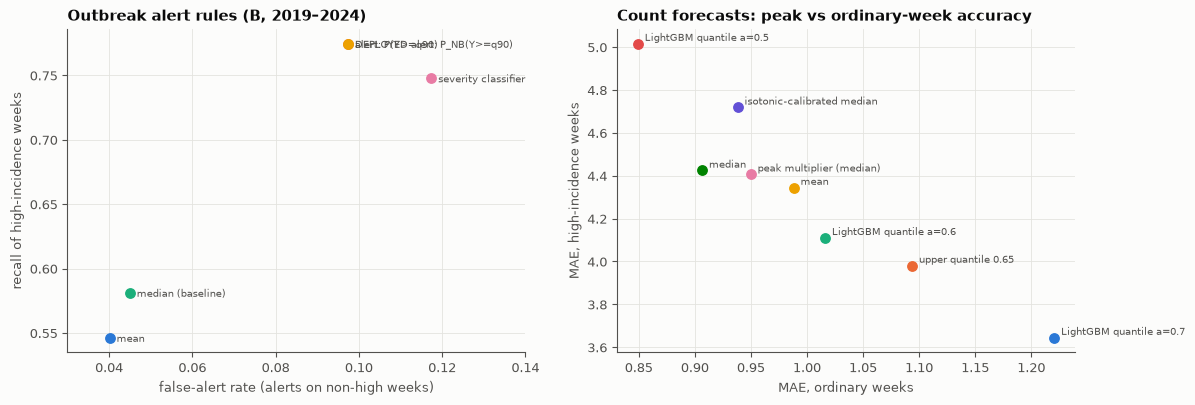

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
det = agg[agg.index.str.contains("alert|classifier") | agg.index.isin(["median (baseline)", "mean"])]
for i, (m, r) in enumerate(det.iterrows()):
    ax[0].scatter(r.false_alert_rate, r.recall, s=46, color=SERIES[i])
    ax[0].annotate(m.replace(" (tuned threshold)", "").replace(" >= tuned", ""), (r.false_alert_rate, r.recall), fontsize=7.5, xytext=(5, -3), textcoords="offset points", color=INK2)
ax[0].set_xlabel("false-alert rate (alerts on non-high weeks)"); ax[0].set_ylabel("recall of high-incidence weeks")
ax[0].set_title("Outbreak alert rules (B, 2019–2024)"); ax[0].set_xlim(0.03, 0.14)
pts = agg.dropna(subset=["high_mae"]).drop(index=[m for m in agg.index if m.startswith("alert")], errors="ignore")
short = {m: m.replace(" on predicted means >= training q80", "").replace(" (Poisson)", "").replace(" (baseline)", "") for m in pts.index}
for i, (m, r) in enumerate(pts.iterrows()):
    ax[1].scatter(r.mae_ordinary, r.high_mae, s=46, color=SERIES[i % 8])
    ax[1].annotate(short[m], (r.mae_ordinary, r.high_mae), fontsize=7.5, xytext=(5, 2), textcoords="offset points", color=INK2)
ax[1].set_xlabel("MAE, ordinary weeks"); ax[1].set_ylabel("MAE, high-incidence weeks"); ax[1].set_title("Count forecasts: peak vs ordinary-week accuracy")
save(fig, "03_peak_tradeoffs")

## 2. Predictive intervals and calibration (nested on the two previous seasons)

In [5]:
cov, prm = I.evaluate(CB, years=S.OUTER)
cov.to_csv(OUT / "interval_coverage_B.csv", index=False); prm.to_csv(OUT / "interval_params_B.csv", index=False)
cs = cov.groupby(["method", "level"])[["coverage", "coverage_high", "coverage_zero", "width", "width_high", "below", "above"]].mean().round(3)
cs.to_csv(OUT / "interval_coverage_summary_B.csv"); D["interval_summary_B"] = cs.reset_index().to_dict("records")
display(cs)
ch = cov.groupby(["method", "level", "horizon"])[["coverage", "width"]].mean().unstack("horizon").round(3); ch

coverage  coverage_high  coverage_zero  width  width_high  below  above
method      level                                                                         
conformal   0.8       0.872          0.574          0.987  3.700       7.734  0.061  0.068
            0.9       0.938          0.736          0.996  5.242      11.669  0.020  0.043
nb_coverage 0.8       0.854          0.607          0.980  3.001       8.168  0.066  0.080
            0.9       0.911          0.740          0.987  4.092      11.409  0.035  0.054
nb_moment   0.8       0.912          0.759          0.985  4.215      13.093  0.027  0.061
            0.9       0.951          0.856          0.992  5.447      16.881  0.011  0.038
poisson     0.8       0.854          0.605          0.980  2.990       8.121  0.066  0.080
            0.9       0.900          0.709          0.986  3.839      10.405  0.042  0.058

coverage                width              
horizon                  2      3      4      2      3      4
method      level                                            
conformal   0.8      0.885  0.867  0.863  3.085  3.735  4.280
            0.9      0.945  0.934  0.934  4.553  5.221  5.951
nb_coverage 0.8      0.888  0.850  0.825  2.809  2.996  3.196
            0.9      0.930  0.901  0.901  3.629  3.968  4.678
nb_moment   0.8      0.920  0.908  0.908  3.530  4.215  4.901
            0.9      0.957  0.948  0.948  4.570  5.448  6.323
poisson     0.8      0.887  0.850  0.824  2.799  2.986  3.184
            0.9      0.929  0.895  0.875  3.616  3.836  4.065

In [6]:
# choose the deployed interval method: closest to nominal coverage on outer seasons (both levels), then narrower
sel = cov.groupby(["method", "level"]).agg(coverage=("coverage", "mean"), width=("width", "mean")).reset_index()
sel["gap"] = (sel["coverage"] - sel["level"]).abs()
rank = sel.groupby("method").agg(gap=("gap", "mean"), width=("width", "mean")).sort_values(["gap", "width"])
best_method = rank.index[0] if rank.index[0] != "poisson" else rank.index[1]
D["interval_method"] = best_method; print("deployed interval method:", best_method); rank.round(3)

deployed interval method: nb_coverage


,gap,width
method,,
poisson,0.027,3.414
nb_coverage,0.032,3.546
conformal,0.055,4.471
nb_moment,0.081,4.831


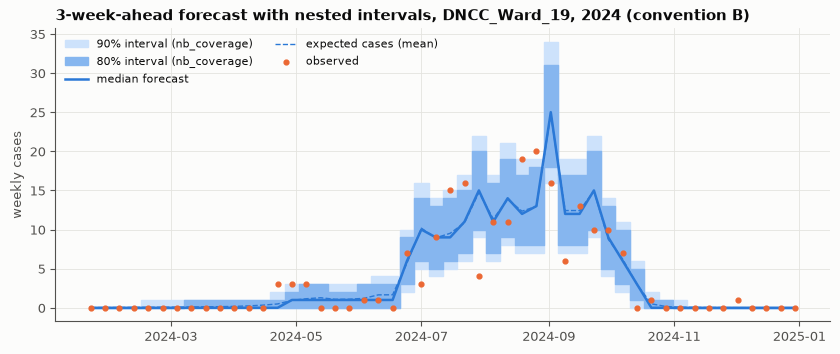

In [7]:
# uncertainty visualisation: one ward, 2024 (an outer validation season), h=3, nested 80% and 90% intervals
ward = CB[(CB.year == 2024) & (CB.horizon == 3)].groupby("ward_id").y_true.sum().idxmax()
fig, ax = plt.subplots(figsize=(10, 3.8))
for lv, col in ((0.9, "#cde2fb"), (0.8, "#86b6ef")):
    inner = CB[(CB.horizon == 3) & CB.year.isin(S.inner_seasons(2024))]
    pr = I.fit_params(inner, lv)
    d = CB[(CB.year == 2024) & (CB.horizon == 3) & (CB.ward_id == ward)].sort_values("target_date")
    lo, hi = I.intervals(d, pr, lv)[best_method]
    ax.fill_between(d.target_date, lo, hi, step="mid", color=col, label=f"{int(lv * 100)}% interval ({best_method})")
ax.plot(d.target_date, poisson.median(np.maximum(d.mu, 1e-9)), color=SERIES[0], lw=1.8, label="median forecast")
ax.plot(d.target_date, d.mu, color=SERIES[0], lw=1, ls="--", label="expected cases (mean)")
ax.scatter(d.target_date, d.y_true, s=12, color=SERIES[1], zorder=3, label="observed")
ax.set_ylabel("weekly cases"); ax.set_title(f"3-week-ahead forecast with nested intervals, {ward}, 2024 (convention B)"); ax.legend(fontsize=8, ncol=2)
save(fig, "04_uncertainty_fan_example")

## 3. Risk tiers (Low / Medium / High / Critical)

Cut points are quantiles of each fold's **training** targets: q60, q80, q95 (1, 5–6 and 13 cases). These are statistical
categories for this synthetic dataset, **not** clinical or national warning levels. "Significant risk" = High or Critical.

In [8]:
from scipy.stats import nbinom
schemes, cms = [], {}
pB = CB[CB.year.isin(S.OUTER)].reset_index(drop=True)
med, mean = poisson.median(np.maximum(pB.mu, 1e-9)), pB.mu.to_numpy()
up = pB.mu.to_numpy()   # placeholder replaced below with the calibrated 80% upper bound
ups = []
for (h, yr), g in pB.groupby(["horizon", "year"]):
    pr = I.fit_params(CB[(CB.horizon == h) & CB.year.isin(S.inner_seasons(yr))], 0.8)
    ups.append(pd.Series(I.intervals(g, pr, 0.8)[best_method][1], index=g.index))
up = pd.concat(ups).sort_index().to_numpy()
for name, point in (("median", med), ("mean", mean), ("upper 80% bound", up)):
    s, cm = R.evaluate(pB, point, name)
    s["revision_flip_rate"] = R.revision_flips(pB, point)
    schemes.append(s); cms[name] = cm
schemes = pd.DataFrame(schemes).set_index("scheme"); schemes.round(3).to_csv(OUT / "risk_tier_schemes.csv")
for n, cm in cms.items(): cm.to_csv(OUT / f"risk_confusion_{n.replace(' ', '_').replace('%', 'pct')}.csv")
D["risk_schemes"] = schemes.round(4).reset_index().to_dict("records")
display(schemes.round(3)); cms["median"]

,accuracy,within_one_tier,sig_recall,sig_precision,sig_false_alert_rate,pred_share_Low,pred_share_Medium,pred_share_High,pred_share_Critical,actual_share_Low,actual_share_Medium,actual_share_High,actual_share_Critical,revision_flip_rate
scheme,,,,,,,,,,,,,,
median,0.745,0.994,0.881,0.764,0.082,0.544,0.188,0.231,0.036,0.551,0.217,0.173,0.059,0.210
mean,0.743,0.993,0.855,0.776,0.074,0.597,0.148,0.223,0.033,0.551,0.217,0.173,0.059,0.207
upper 80% bound,0.530,0.977,0.973,0.682,0.137,0.274,0.395,0.210,0.121,0.551,0.217,0.173,0.059,0.320


predicted,Low,Medium,High,Critical
actual,,,,
Low,26080,3042,122,0
Medium,2811,5498,3101,122
High,10,1389,6984,797
Critical,0,68,2073,1003


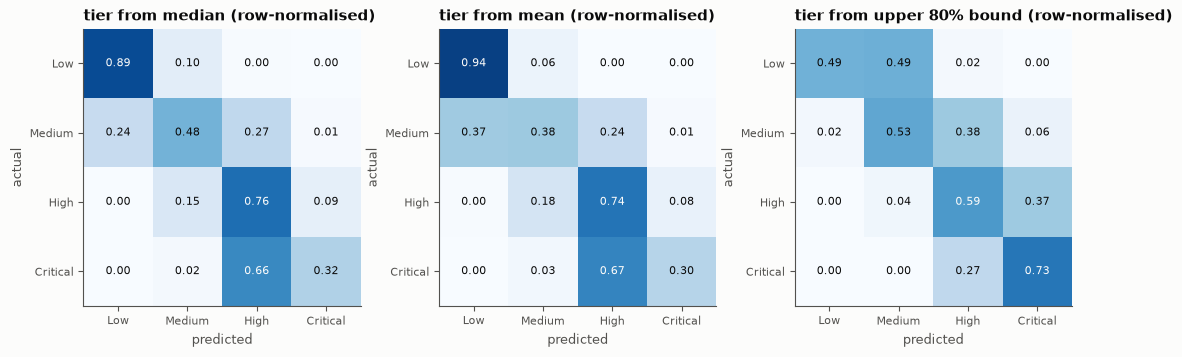

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (n, cm) in zip(ax, cms.items()):
    m = cm.to_numpy(float); m = m / m.sum(axis=1, keepdims=True)
    a.imshow(m, cmap="Blues", vmin=0, vmax=1); a.grid(False)
    for i in range(4):
        for j in range(4):
            a.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=8, color=SURF if m[i, j] > 0.55 else INK)
    a.set_xticks(range(4)); a.set_xticklabels(R.TIERS, fontsize=8); a.set_yticks(range(4)); a.set_yticklabels(R.TIERS, fontsize=8)
    a.set_xlabel("predicted"); a.set_ylabel("actual"); a.set_title(f"tier from {n} (row-normalised)")
save(fig, "05_risk_confusion")

## 4. Interpretability for the finalists (descriptive, not causal)

In [10]:
GROUPS = {
    "rain at target-lag 3": lambda c: c in ("rain_tl3",),
    "other aligned rain (lags 2,4,5 + window)": lambda c: c.startswith("rain_tl") and c != "rain_tl3" and not c.endswith("_obs") or c == "rain_win",
    "rain climatology / regime": lambda c: c.startswith(("rain_clim", "rain_pwet", "regime", "rain_anom")) or c.startswith("monsoon") or c.startswith("weeks_since"),
    "observation flags": lambda c: c.endswith("_obs") or c == "rain_win_nobs",
    "calendar": lambda c: c.startswith("cal_"),
    "ward vulnerability": lambda c: c in ("pop_density", "log_pop_density", "waterlogging", "sanitation"),
}
def group_of(c):
    for g, f in GROUPS.items():
        if f(c): return g
    return "other"
finalists = {"champion": (CH["per_horizon"]["3"]["model"], CH["per_horizon"]["3"]["params"], CH["per_horizon"]["3"]["fs"]),
             "LightGBM Poisson (untuned)": ("lgbm_poisson", {}, "F3")}
rng = np.random.default_rng(2026); rows = []
for label, (model, params, fs) in finalists.items():
    cols = FS[fs]
    for yr in S.OUTER:
        for h in (2, 3, 4):
            sd = S.season_data(panel, "B", yr, h, cols)
            m = make(model, **params).fit(sd.Xtr[cols], sd.ytr, years=sd.years)
            base = np.mean(np.abs(m.dist(m.predict_params(sd.Xev[cols])).median() - sd.yev))
            for g in GROUPS:
                gc = [c for c in cols if group_of(c) == g]
                if not gc: continue
                inc = []
                for r in range(3):
                    Xp = sd.Xev[cols].copy(); Xp[gc] = sd.Xev[gc].to_numpy()[rng.permutation(len(Xp))]
                    inc.append(np.mean(np.abs(m.dist(m.predict_params(Xp)).median() - sd.yev)) - base)
                rows.append({"model": label, "year": yr, "horizon": h, "group": g, "mae_increase": float(np.mean(inc))})
perm = pd.DataFrame(rows); perm.to_csv(OUT / "permutation_importance_groups_B.csv", index=False)
pg = perm.groupby(["model", "group"]).mae_increase.mean().unstack("model").sort_values(list(finalists)[0], ascending=False)
D["permutation_groups"] = pg.round(4).to_dict()
stab = perm.groupby(["model", "year", "group"]).mae_increase.mean().unstack("group")
rank_stab = {m: float(stab.loc[m].rank(axis=1).T.corr(method="spearman").values[np.triu_indices(len(S.OUTER), 1)].mean()) for m in finalists}
D["importance_rank_stability_mean_spearman_between_years"] = rank_stab
print("mean Spearman correlation of group rankings between seasons:", rank_stab); pg.round(3)

mean Spearman correlation of group rankings between seasons: {'champion': 0.44000000000000006, 'LightGBM Poisson (untuned)': 0.6000000000000001}


model,LightGBM Poisson (untuned),champion
group,,
calendar,1.388,1.644
rain at target-lag 3,0.145,0.829
rain climatology / regime,0.137,0.348
"other aligned rain (lags 2,4,5 + window)",0.177,0.323
ward vulnerability,0.246,0.261
observation flags,0.000,NaN


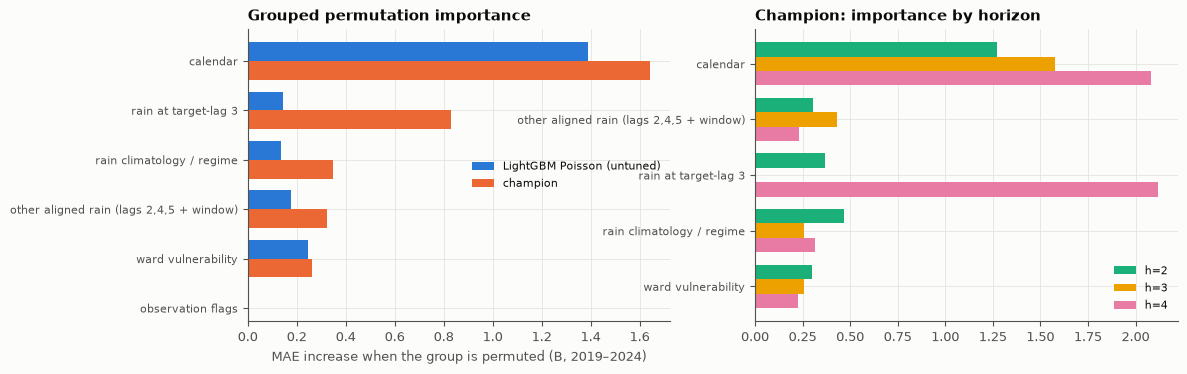

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
y = np.arange(len(pg))
for i, m in enumerate(pg.columns):
    ax[0].barh(y + (i - 0.5) * 0.38, pg[m], 0.38, color=SERIES[i], label=m)
ax[0].set_yticks(y); ax[0].set_yticklabels(pg.index, fontsize=8); ax[0].invert_yaxis(); ax[0].legend(fontsize=8)
ax[0].set_xlabel("MAE increase when the group is permuted (B, 2019–2024)"); ax[0].set_title("Grouped permutation importance")
ph = perm[perm.model == "champion"].groupby(["horizon", "group"]).mae_increase.mean().unstack("horizon")
for i, h in enumerate(ph.columns):
    ax[1].barh(np.arange(len(ph)) + (i - 1) * 0.26, ph[h], 0.26, color=SERIES[i + 2], label=f"h={h}")
ax[1].set_yticks(range(len(ph))); ax[1].set_yticklabels(ph.index, fontsize=8); ax[1].invert_yaxis(); ax[1].legend(fontsize=8)
ax[1].set_title("Champion: importance by horizon")
save(fig, "06_permutation_importance")

In [12]:
# champion GLM coefficients (standardised inputs) on the final 2016-2024 fit for B, h=3: ward vulnerability and rain effects
c = CH["per_horizon"]["3"]; cols = FS[c["fs"]]
sd = S.season_data(panel, "B", 2024, 3, cols)
m = make(c["model"], **c["params"]).fit(sd.Xtr[cols], sd.ytr, years=sd.years)
names = list(np.asarray(m._design(sd.Xtr[cols]).columns)[m.st[-1]]) if hasattr(m, "_design") else cols
coef = pd.Series(m.reg.coef_, index=names).sort_values(key=np.abs, ascending=False)
coef.round(4).to_csv(OUT / "champion_glm_standardised_coefficients_h3.csv")
D["glm_top_coefficients_h3"] = coef.head(12).round(4).to_dict()
coef.head(15).round(3)

cal_org_cos1       -0.769
cal_tgt_cos1       -0.746
cal_org_monsoon     0.553
rain_pwet_tl3       0.539
cal_org_sin2        0.318
rain_tl4            0.310
rain_clim_target   -0.253
cal_org_cos2       -0.241
waterlogging        0.209
cal_tgt_sin1       -0.196
cal_tgt_sin3        0.180
rain_win           -0.176
pop_density         0.114
rain_tl2           -0.083
cal_tgt_sin2        0.080
dtype: float64

In [13]:
# TreeSHAP for the boosting finalist on 1,500 rows of 2024, h=3, convention B
from dengueshield.models.zoo import LGBMCount
sd = S.season_data(panel, "B", 2024, 3, FS["F3"])
lg = make("lgbm_poisson").fit(sd.Xtr[FS["F3"]], sd.ytr, years=sd.years)
samp = sd.Xev[FS["F3"]].sample(1500, random_state=2026)
sv = lg.m.booster_.predict(samp, pred_contrib=True)
assert np.abs(sv.sum(1) - lg.m.booster_.predict(samp, raw_score=True)).max() < 1e-6
shap = pd.Series(np.abs(sv[:, :-1]).mean(0), index=FS["F3"]).sort_values(ascending=False)
shap.round(4).to_csv(OUT / "shap_lgbm_B_2024_h3.csv"); D["shap_lgbm_top10"] = shap.head(10).round(4).to_dict()
shap.groupby(shap.index.map(group_of)).sum().sort_values(ascending=False).round(3)

calendar                                    2.162
rain climatology / regime                   0.325
other aligned rain (lags 2,4,5 + window)    0.234
ward vulnerability                          0.131
rain at target-lag 3                        0.025
observation flags                           0.000
dtype: float64

## 5. Deployable bundles (convention B primary, A secondary)

In [14]:
from dengueshield.inference import ForecastBundle, build_bundle
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
data_hash = sha256(RAW_PATH)
def calib_for(preds, h):
    inner = preds[(preds.horizon == h) & preds.year.isin([2023, 2024])]          # seasons before the 2025 holdout
    out = {}
    for lv in (0.8, 0.9):
        pr = I.fit_params(inner, lv)
        out[lv] = {"method": best_method, "alpha": pr["alpha_cov"] if best_method != "nb_moment" else pr["alpha_moment"], "q": pr["conformal_q"],
                   "fitted_on_seasons": [2023, 2024]}
    return out
def alert_for(preds, h):
    # same rule as validated: P_NB(Y >= q90) with the stored alpha; cut maximises F1 on seasons 2023-2024
    inner = preds[(preds.horizon == h) & preds.year.isin([2023, 2024])]
    a_ = calib_for(preds, h)[0.8]["alpha"]                                  # exactly the alpha the bundle uses for p_outbreak
    p = nbinom.sf(np.ceil(inner.thr_q90) - 1, 1 / a_, 1 / (1 + a_ * np.maximum(inner.mu, 1e-9)))
    return PK._best_f1_threshold(p, inner.y_true.to_numpy(float), inner.thr_q90.to_numpy(float))
bundles = {}
for conv_key, conv_name, wl, cl, preds in (("B", "B_start_of_week", 1, 1, CB), ("A", "A_end_of_week", 0, 0, CA)):
    specs = {h: (CH["per_horizon"][str(h)]["model"], CH["per_horizon"][str(h)]["params"], FS[CH["per_horizon"][str(h)]["fs"]]) for h in (2, 3, 4)}
    val = {h: CH["validation"][conv_key][str(h)] for h in (2, 3, 4)}
    t0 = time.perf_counter()
    b = build_bundle(panel, conv_name, wl, cl, specs, {h: calib_for(preds, h) for h in (2, 3, 4)}, {h: alert_for(preds, h) for h in (2, 3, 4)},
                     val, data_sha256=data_hash, notes="Trained on 2016-2024 labels reported by 2024-12-31. 2025 never used.")
    path = MODELS / f"dengueshield_{conv_key}.joblib"
    digest = b.save(path)
    bundles[conv_key] = {"path": str(path.relative_to(ROOT)), "sha256": digest, "build_s": time.perf_counter() - t0, "bytes": path.stat().st_size}
D["bundles"] = bundles; bundles

{'B': {'path': 'models/dengueshield_B.joblib',
  'sha256': '133d7d322c2fc52785f2a5b0b32595b8a3d089a8f5d305baf6226bd7501f5e3b',
  'build_s': 7.574669791967608,
  'bytes': 11028},
 'A': {'path': 'models/dengueshield_A.joblib',
  'sha256': 'f12a558dc8ec916172c484e3e7222d27c352a9f39147805b7fe8ce61ba743940',
  'build_s': 7.844381875009276,
  'bytes': 10990}}

In [15]:
# from-scratch load parity and inference benchmarks (convention B)
b = ForecastBundle.load(ROOT / bundles["B"]["path"])
origin = panel.date.max() + pd.Timedelta(weeks=1)                      # first B origin after the record: uses weeks <= 2024-12-30
pred1 = b.predict(panel, origin, 3)
build = build_bundle  # noqa
again = ForecastBundle.load(ROOT / bundles["B"]["path"]).predict(panel, origin, 3)
pd.testing.assert_frame_equal(pred1, again)
def bench(fn, n=5):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts)) * 1000
w1 = b.wards.ward_id.iloc[0]
bm = {"single ward, one horizon (ms)": bench(lambda: b.predict(panel, origin, 3, wards=[w1])),
      "all 60 wards, one horizon (ms)": bench(lambda: b.predict(panel, origin, 3)),
      "all 60 wards x 3 horizons (ms)": bench(lambda: [b.predict(panel, origin, h) for h in (2, 3, 4)]),
      "explain, all wards, one horizon (ms)": bench(lambda: b.explain(panel, origin, 3)),
      "load bundle from disk (ms)": bench(lambda: ForecastBundle.load(ROOT / bundles["B"]["path"]), 3)}
D["inference_benchmarks_ms"] = {k: round(v, 1) for k, v in bm.items()}
print(json.dumps(D["inference_benchmarks_ms"], indent=1))
pred1.head(8)

{
 "single ward, one horizon (ms)": 127.6,
 "all 60 wards, one horizon (ms)": 129.1,
 "all 60 wards x 3 horizons (ms)": 379.1,
 "explain, all wards, one horizon (ms)": 125.2,
 "load bundle from disk (ms)": 2.1
}


,ward_id,city,origin_date,target_date,horizon,expected_cases,median_cases,lower_80,upper_80,lower_90,upper_90,p_outbreak,outbreak_alert,risk_tier,convention,model
0,CCC_Ward_01,Chattogram,2025-01-06,2025-01-27,3,0.208327,0.0,0.0,1.0,0.0,1.0,1.747699e-12,False,Low,B_start_of_week,glm_poisson
1,CCC_Ward_02,Chattogram,2025-01-06,2025-01-27,3,0.104018,0.0,0.0,0.0,0.0,1.0,3.705030e-15,False,Low,B_start_of_week,glm_poisson
2,CCC_Ward_03,Chattogram,2025-01-06,2025-01-27,3,0.215707,0.0,0.0,1.0,0.0,1.0,2.374835e-12,False,Low,B_start_of_week,glm_poisson
3,CCC_Ward_04,Chattogram,2025-01-06,2025-01-27,3,0.141359,0.0,0.0,1.0,0.0,1.0,5.662756e-14,False,Low,B_start_of_week,glm_poisson
4,CCC_Ward_05,Chattogram,2025-01-06,2025-01-27,3,0.098996,0.0,0.0,0.0,0.0,1.0,2.384344e-15,False,Low,B_start_of_week,glm_poisson
5,CCC_Ward_06,Chattogram,2025-01-06,2025-01-27,3,0.124078,0.0,0.0,1.0,0.0,1.0,1.778999e-14,False,Low,B_start_of_week,glm_poisson
6,CCC_Ward_07,Chattogram,2025-01-06,2025-01-27,3,0.156049,0.0,0.0,1.0,0.0,1.0,1.360469e-13,False,Low,B_start_of_week,glm_poisson
7,CCC_Ward_08,Chattogram,2025-01-06,2025-01-27,3,0.130641,0.0,0.0,1.0,0.0,1.0,2.812294e-14,False,Low,B_start_of_week,glm_poisson


In [16]:
try:
    b.predict(panel, origin + pd.Timedelta(weeks=1), 3)
except ValueError as e:
    print("refused as intended:", e)
(OUT / "diagnostics_summary.json").write_text(json.dumps(D, indent=2, default=float))
print("saved diagnostics_summary.json")

refused as intended: origin 2025-01-13 needs observations up to 2025-01-06, but the data end on 2024-12-30; forecasts beyond the observed record are refused, not extrapolated
saved diagnostics_summary.json
